# 03 Clustering dengan Label Tersembunyi

Teks dikelompokkan tanpa label, tapi penilaiannya memakai label tersembunyi lewat NMI atau ARI.
Contoh: judul berita Indonesia dengan kategori disembunyikan.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Mengelompokkan teks yang label aslinya tersembunyi |
| **Unit prediksi** | Satu judul mendapat satu cluster |
| **Metrik** | Saat lomba tanpa label: stabilitas. Audit di sini: NMI, ARI |
| **Masalah terbesar** | Silhouette menyesatkan: Spearman silhouette terhadap NMI -0,946. Skor silhouette tertinggi justru berasal dari cluster timpang yang hampir tidak bermakna. |
| **Data contoh** | 5.000 judul berita, kategori asli hanya untuk audit |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal meminta mengelompokkan teks, dan leaderboard menilai dengan NMI, ARI, V-measure,
atau akurasi hasil pencocokan. Kalau penilaiannya coherence atau kualitas topik, pakai folder `01`.

**Yang perlu diganti kalau datanya beda:**
- `load_data` dan `TEXT_COL`. Di soal asli kolom `category` tidak ada, jadi hapus sel audit.
- `N_CLUSTERS`, isi kalau soal menyebut jumlahnya. Kalau tidak, biarkan `None`.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: embedding memakai TF-IDF + SVD, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
TEXT_COL, HIDDEN_LABEL_COL = "title", "category"
N_CLUSTERS = None  # None: ditentukan dari stabilitas
MAX_CLUSTER_SHARE = 0.5

SETTINGS = {
    "cepat": {"k_grid": [6, 9, 12], "bag_seeds": 5},
    "penuh": {"k_grid": [5, 6, 7, 8, 9, 10, 12, 15], "bag_seeds": 20},
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'k_grid': [5, 6, 7, 8, 9, 10, 12, 15], 'bag_seeds': 20}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Stopword.** Daftar ini hanya dipakai untuk merangkum kata kunci topik, bukan untuk input model
embedding. Tambahkan kata yang terlalu umum di kasus lu, misalnya `mbg` dan `makan`.

In [6]:
STOPWORDS = set(
    """
    ada adalah agar akan aku anda apa apakah atas atau bagaimana bagi bahkan bahwa banyak baru
    begitu belum benar berapa bersama bisa buat bukan cuma dalam dan dapat dari dengan di dia
    dong dulu gak ga gitu gue gua hanya harus hal ini itu iya jadi jangan juga jika kalau kalo
    kami kamu kan karena kata ke kita kok lagi lah lain lalu lebih lu lo masih mau maka mana
    memang mereka meski mungkin nah nanti ni nya oleh pada pak para pun punya saat saja sama
    sampai saya sebagai sebagainya sedang sudah sudah sih seperti siapa supaya tak tapi telah
    tentang terus tetapi tidak tuh udah untuk ya yaitu yang yg dgn dg krn utk tdk jg aja kalo
    aja nih deh kak bang bu ibu bapak sekarang semua setiap sangat tanpa ketika orang enggak
    quot amp mas mbak sih dah tau kayak kaya sampe gimana emang kenapa
    """.split()
)

**Embedding teks.** Kalau pretrained boleh dipakai, teks diubah dengan multilingual-e5. Kalau
tidak boleh, `USE_PRETRAINED=False` memakai TF-IDF + SVD sebagai gantinya.

In [7]:
from sklearn.decomposition import TruncatedSVD  # noqa: E402
from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf  # noqa: E402
from sklearn.preprocessing import normalize as _l2  # noqa: E402
from transformers import AutoModel, AutoTokenizer  # noqa: E402


def tfidf_svd_embed(texts: list[str], dim: int = 256) -> np.ndarray:
    """Embedding tanpa pretrained: TF-IDF kata + SVD."""
    matrix = _Tfidf(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    dim = min(dim, matrix.shape[1] - 1, matrix.shape[0] - 1)
    return _l2(TruncatedSVD(dim, random_state=SEED).fit_transform(matrix))


@torch.inference_mode()
def e5_embed(texts: list[str], prefix: str = "query: ", batch_size: int = 64) -> np.ndarray:
    """Mean pooling multilingual-e5, hasil dinormalisasi L2."""
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / "e5")
    model = AutoModel.from_pretrained(MODEL_DIR / "e5").to(DEVICE).eval().half()
    order = np.argsort([len(t) for t in texts])
    chunks = []
    for start in range(0, len(texts), batch_size):
        batch = [prefix + texts[i] for i in order[start : start + batch_size]]
        tokens = tokenizer(
            batch, padding=True, truncation=True, max_length=128, return_tensors="pt"
        ).to(DEVICE)
        hidden = model(**tokens).last_hidden_state
        mask = tokens["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        chunks.append(torch.nn.functional.normalize(pooled, dim=1).float().cpu().numpy())
    del model
    torch.cuda.empty_cache()
    vectors = np.empty((len(texts), chunks[0].shape[1]), dtype=np.float32)
    vectors[order] = np.vstack(chunks)
    return vectors


def embed_texts(texts: list[str]) -> np.ndarray:
    """Pilih embedding sesuai USE_PRETRAINED."""
    return e5_embed(texts) if USE_PRETRAINED else tfidf_svd_embed(texts)

## 4. EDA

Muat data. Kolom kategori disisihkan dan hanya dipakai untuk audit di bagian akhir.

In [8]:
def load_data() -> pd.DataFrame:
    frame = pd.read_csv(find_file("indonesian-news-title.csv")).dropna(subset=[TEXT_COL])
    return frame.sample(n=min(N_ROWS, len(frame)), random_state=SEED).reset_index(drop=True)


data = load_data()
hidden_labels = data.pop(HIDDEN_LABEL_COL)
print(f"baris: {len(data)}")
text_profile(data[TEXT_COL])

baris: 5000


baris                5000.0
kosong                  0.0
duplikat_persis_%       0.0
kata_median             9.0
kata_p95               12.0
kata_maks              18.0
ada_url_%               0.0
ada_emoji_%             0.0
dtype: float64

Contoh judul, kata terbanyak, dan distribusi kategori tersembunyi. Yang terakhir hanya boleh dilihat
di latihan ini.

                    Pasien Eka Hospital Bogor yang Negatif Corona Masih Dirawat
                Video Warga Natuna Ramai-ramai Demo Tolak Jadi Tempat Karantina
Update Corona di RI 5 Juni: Kasus Positif 29.521, Sembuh 9.443, Meninggal 1.770
       Kepsek Harap RK-Walkot Bekasi Relokasi Gedung SDN Jatirasa V Usai Banjir


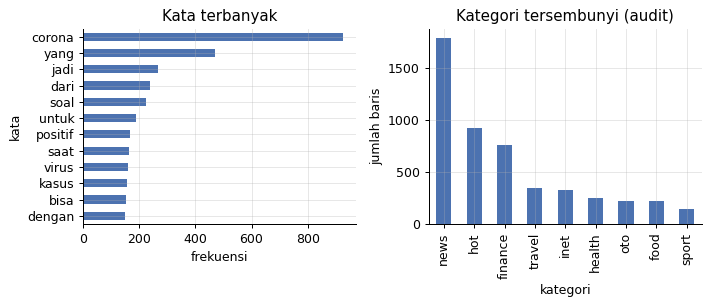

In [9]:
print(data[TEXT_COL].head(4).to_string(index=False))
words = data[TEXT_COL].str.lower().str.findall(r"[a-z]{4,}").explode()
fig, axes = plt.subplots(1, 2)
words.value_counts().head(12).sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title="Kata terbanyak", xlabel="frekuensi", ylabel="kata")
hidden_labels.value_counts().plot.bar(ax=axes[1], color="#4C72B0")
axes[1].set(title="Kategori tersembunyi (audit)", xlabel="kategori", ylabel="jumlah baris")
plt.tight_layout()
plt.show()

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Judul sangat pendek: median 9 kata, tanpa duplikat | Pembersihan cukup huruf kecil dan spasi, stopword tetap dipertahankan |
| Berita corona mendominasi | Satu cluster besar wajar, tapi cluster terlalu timpang ditolak |
| Embed + agglomerative punya silhouette 0,2272 tapi NMI 0,0057 | Pilih model dari stabilitas, bukan silhouette |

## 5. Preprocessing

Judul sudah bersih, jadi cukup huruf kecil dan spasi. Stopword tidak dibuang karena model embedding
memakai kalimat utuh.

In [10]:
data["clean"] = data[TEXT_COL].map(clean_text)
print("duplikat setelah dibersihkan:", int(data["clean"].duplicated().sum()))

duplikat setelah dibersihkan: 0


## 6. Validasi

Di soal asli label tidak ada, jadi pemilihan model **tidak boleh** memakai label. NMI, ARI, dan akurasi hasil
pencocokan dihitung sebagai audit dan tidak ikut memilih. Metrik diuji dulu.

In [11]:
from scipy.optimize import linear_sum_assignment  # noqa: E402
from sklearn.metrics import (  # noqa: E402
    adjusted_rand_score,
    confusion_matrix,
    normalized_mutual_info_score,
    silhouette_score,
    v_measure_score,
)


def matched_accuracy(truth, labels) -> float:
    """Akurasi setelah cluster dicocokkan dengan kategori memakai algoritma Hungarian."""
    truth_ids = pd.factorize(truth)[0]
    labels_ids = pd.factorize(labels)[0]
    size = max(truth_ids.max(), labels_ids.max()) + 1
    table = confusion_matrix(truth_ids, labels_ids, labels=range(size))
    rows, cols = linear_sum_assignment(-table)
    return float(table[rows, cols].sum() / len(truth_ids))


assert matched_accuracy(["a", "a", "b", "b"], [1, 1, 0, 0]) == 1.0
assert matched_accuracy(["a", "a", "b", "b"], [0, 1, 0, 1]) == 0.5

results: list[dict] = []


def record(name: str, labels: np.ndarray, vectors: np.ndarray) -> None:
    results.append(
        {
            "model": name,
            "k": int(len(np.unique(labels))),
            "silhouette": round(
                float(
                    silhouette_score(
                        vectors, labels, metric="cosine", sample_size=3000, random_state=SEED
                    )
                ),
                4,
            ),
            "nmi_audit": round(normalized_mutual_info_score(hidden_labels, labels), 4),
            "ari_audit": round(adjusted_rand_score(hidden_labels, labels), 4),
            "v_audit": round(v_measure_score(hidden_labels, labels), 4),
            "acc_audit": round(matched_accuracy(hidden_labels, labels), 4),
        }
    )

## 7. Baseline

TF-IDF + SVD + KMeans, tanpa model dari luar.

In [12]:
from sklearn.cluster import AgglomerativeClustering, KMeans  # noqa: E402

runs: dict[str, np.ndarray] = {}
with stage("baseline"):
    vectors_tfidf = tfidf_svd_embed(data["clean"].tolist())
    for k in SETTINGS["k_grid"]:
        runs[f"tfidf_kmeans_{k}"] = KMeans(k, random_state=SEED, n_init=10).fit_predict(
            vectors_tfidf
        )
        record(f"tfidf_kmeans_{k}", runs[f"tfidf_kmeans_{k}"], vectors_tfidf)
pd.DataFrame(results)

[waktu] baseline: 12 detik


,model,k,silhouette,nmi_audit,ari_audit,v_audit,acc_audit
0,tfidf_kmeans_5,5,0.0337,0.0432,0.0140,0.0432,0.2572
1,tfidf_kmeans_6,6,0.0305,0.0408,0.0001,0.0408,0.2480
2,tfidf_kmeans_7,7,0.0408,0.0450,0.0186,0.0450,0.2482
3,tfidf_kmeans_8,8,0.0406,0.0483,0.0094,0.0483,0.2344
4,tfidf_kmeans_9,9,0.0425,0.0506,0.0155,0.0506,0.2462
5,tfidf_kmeans_10,10,0.0470,0.0463,0.0185,0.0463,0.2400
6,tfidf_kmeans_12,12,0.0555,0.0540,0.0102,0.0540,0.2246
7,tfidf_kmeans_15,15,0.0660,0.0505,0.0066,0.0505,0.2014


## 8. Model Utama

Embedding + KMeans dan agglomerative, dengan dua pilihan ruang: embedding langsung dan hasil UMAP.

In [13]:
import umap  # noqa: E402

with stage("embedding"):
    embeddings = embed_texts(data["clean"].tolist())
with stage("umap"):
    reduced = umap.UMAP(
        n_neighbors=30, n_components=10, min_dist=0.0, metric="cosine", random_state=SEED
    ).fit_transform(embeddings)

with stage("clustering"):
    for k in SETTINGS["k_grid"]:
        for space, vectors in (("embed", embeddings), ("umap", reduced)):
            name = f"{space}_kmeans_{k}"
            runs[name] = KMeans(k, random_state=SEED, n_init=10).fit_predict(vectors)
            record(name, runs[name], embeddings)
        name = f"embed_agglo_{k}"
        runs[name] = AgglomerativeClustering(k, metric="cosine", linkage="average").fit_predict(
            embeddings
        )
        record(name, runs[name], embeddings)
pd.DataFrame(results).sort_values("silhouette", ascending=False).head(10)

[waktu] embedding: 29 detik


[waktu] umap: 34 detik


[waktu] clustering: 82 detik


,model,k,silhouette,nmi_audit,ari_audit,v_audit,acc_audit
10,embed_agglo_5,5,0.2272,0.0057,0.0009,0.0057,0.3608
13,embed_agglo_6,6,0.2114,0.0063,0.0011,0.0063,0.3610
16,embed_agglo_7,7,0.2114,0.0070,0.0012,0.0070,0.3612
19,embed_agglo_8,8,0.1965,0.0081,0.0014,0.0081,0.3612
22,embed_agglo_9,9,0.1887,0.0081,0.0014,0.0081,0.3610
25,embed_agglo_10,10,0.1844,0.0092,0.0017,0.0092,0.3614
28,embed_agglo_12,12,0.1793,0.0097,0.0017,0.0097,0.3612
31,embed_agglo_15,15,0.1429,0.0159,0.0027,0.0159,0.3624
7,tfidf_kmeans_15,15,0.0660,0.0505,0.0066,0.0505,0.2014
6,tfidf_kmeans_12,12,0.0555,0.0540,0.0102,0.0540,0.2246


## 9. Post-processing

**Silhouette saja menyesatkan.** Agglomerative average sering membuat satu cluster raksasa dan sisanya kecil, dan
itu justru dapat silhouette tinggi. Jadi aturan pemilihannya, tetap tanpa label:
1. Tolak hasil yang timpang, yaitu cluster terbesar melebihi `MAX_CLUSTER_SHARE`.
2. Pilih yang paling **stabil** antar seed, karena struktur asli akan muncul lagi saat seed diganti.

Lalu hasil dimantapkan dengan **consensus**: label dari banyak seed dijadikan fitur, lalu di-cluster lagi.

In [14]:
def largest_share(labels: np.ndarray) -> float:
    return float(np.bincount(pd.factorize(labels)[0]).max() / len(labels))


def stability_score(vectors: np.ndarray, k: int, seeds=(101, 102, 103)) -> float:
    """Rata-rata ARI antar hasil KMeans dengan seed berbeda."""
    labelings = [KMeans(k, random_state=s, n_init=3).fit_predict(vectors) for s in seeds]
    pairs = [(0, 1), (0, 2), (1, 2)]
    return float(np.mean([adjusted_rand_score(labelings[a], labelings[b]) for a, b in pairs]))


selection = pd.DataFrame(results)
selection = selection[selection["model"].str.startswith(("embed_kmeans", "umap_kmeans"))].copy()
selection["terbesar"] = [largest_share(runs[m]) for m in selection["model"]]
selection = selection[selection["terbesar"] <= MAX_CLUSTER_SHARE]
with stage("stabilitas"):
    selection["stabilitas"] = [
        stability_score(reduced if m.startswith("umap") else embeddings, int(k))
        for m, k in zip(selection["model"], selection["k"])
    ]
best = selection.sort_values("stabilitas", ascending=False).iloc[0]
best_k = N_CLUSTERS or int(best["k"])
print(f"dipilih dari stabilitas: {best['model']} -> k={best_k}")
stability_table = selection[
    ["model", "k", "silhouette", "stabilitas", "terbesar", "nmi_audit"]
].round(4)


def consensus_labels(vectors: np.ndarray, k: int, n_seeds: int) -> np.ndarray:
    """KMeans pada label one-hot dari banyak seed: baris yang sering sekelompok jadi berdekatan."""
    columns = []
    for seed in range(n_seeds):
        labels = KMeans(k, random_state=seed, n_init=1).fit_predict(vectors)
        columns.append(np.eye(k, dtype=np.float32)[labels])
    return KMeans(k, random_state=SEED, n_init=10).fit_predict(np.hstack(columns))


with stage("consensus"):
    space_vectors = reduced if str(best["model"]).startswith("umap") else embeddings
    final_labels = consensus_labels(space_vectors, best_k, SETTINGS["bag_seeds"])
record("consensus_final", final_labels, embeddings)
stability_table.sort_values("stabilitas", ascending=False)

[waktu] stabilitas: 20 detik
dipilih dari stabilitas: umap_kmeans_5 -> k=5


[waktu] consensus: 0 detik


,model,k,silhouette,stabilitas,terbesar,nmi_audit
9,umap_kmeans_5,5,0.0210,1.0000,0.2532,0.1539
8,embed_kmeans_5,5,0.0329,0.8703,0.2516,0.0719
12,umap_kmeans_6,6,0.0166,0.8305,0.2222,0.1759
30,umap_kmeans_15,15,0.0153,0.8140,0.1090,0.2339
27,umap_kmeans_12,12,0.0129,0.7953,0.1236,0.2096
24,umap_kmeans_10,10,0.0112,0.7839,0.1258,0.1973
11,embed_kmeans_6,6,0.0333,0.7688,0.1910,0.0997
21,umap_kmeans_9,9,0.0104,0.7213,0.1916,0.1954
26,embed_kmeans_12,12,0.0205,0.7182,0.1172,0.1532
17,embed_kmeans_8,8,0.0205,0.6901,0.1510,0.1207


## 10. Post-analysis

**Tabel perbandingan,** diurutkan menurut NMI audit.

In [15]:
result_table = pd.DataFrame(results).sort_values("nmi_audit", ascending=False)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table.head(10)

,model,k,silhouette,nmi_audit,ari_audit,v_audit,acc_audit
30,umap_kmeans_15,15,0.0153,0.2339,0.1094,0.2339,0.2560
27,umap_kmeans_12,12,0.0129,0.2096,0.0989,0.2096,0.2648
24,umap_kmeans_10,10,0.0112,0.1973,0.1012,0.1973,0.2788
21,umap_kmeans_9,9,0.0104,0.1954,0.1101,0.1954,0.3016
18,umap_kmeans_8,8,0.0139,0.1834,0.1064,0.1834,0.3034
12,umap_kmeans_6,6,0.0166,0.1759,0.1251,0.1759,0.3286
29,embed_kmeans_15,15,0.0214,0.1756,0.0760,0.1756,0.2152
15,umap_kmeans_7,7,0.0152,0.1693,0.0934,0.1693,0.2932
9,umap_kmeans_5,5,0.0210,0.1539,0.1055,0.1539,0.3408
32,consensus_final,5,0.0211,0.1538,0.1053,0.1538,0.3406


**Apakah metrik tanpa label bisa dipercaya?** Korelasi silhouette dan stabilitas dengan NMI audit. Kalau korelasinya
rendah atau negatif, jangan menyetel terlalu halus berdasarkan metrik itu.

In [16]:
correlation = result_table[["silhouette", "nmi_audit"]].corr(method="spearman").iloc[0, 1]
stability_correlation = (
    stability_table[["stabilitas", "nmi_audit"]].corr(method="spearman").iloc[0, 1]
)
print(f"Spearman silhouette-NMI: {correlation:.3f} | stabilitas-NMI: {stability_correlation:.3f}")

Spearman silhouette-NMI: -0.946 | stabilitas-NMI: 0.229


**Isi tiap cluster:** kata khas dan kategori tersembunyi yang paling sering muncul.

In [17]:
vectorizer = TfidfVectorizer(
    min_df=5, max_df=0.3, token_pattern=r"\b[a-z]{3,}\b", stop_words=sorted(STOPWORDS)
)
tfidf_matrix = vectorizer.fit_transform(data["clean"])
vocab = np.array(vectorizer.get_feature_names_out())
rows = []
for cluster in np.unique(final_labels):
    members = final_labels == cluster
    top = np.asarray(tfidf_matrix[members].mean(0)).ravel().argsort()[::-1][:6]
    rows.append(
        {
            "cluster": int(cluster),
            "jumlah": int(members.sum()),
            "kata_khas": ", ".join(vocab[top]),
            "kategori_audit": hidden_labels[members]
            .value_counts(normalize=True)
            .round(2)
            .head(2)
            .to_dict(),
        }
    )
pd.DataFrame(rows).sort_values("jumlah", ascending=False)

,cluster,jumlah,kata_khas,kategori_audit
2,2,1266,"corona, positif, virus, pasien, kasus, pandemi","{'news': 0.37, 'finance': 0.23}"
0,0,1264,"jokowi, corona, soal, mudik, anies, dki","{'news': 0.51, 'finance': 0.24}"
1,1,998,"soal, anak, meninggal, kasus, kpk, eks","{'hot': 0.57, 'news': 0.22}"
3,3,997,"mobil, foto, hingga, indonesia, tahun, makan","{'food': 0.17, 'inet': 0.16}"
4,4,475,"banjir, polisi, tewas, warga, korban, pria","{'news': 0.8, 'oto': 0.05}"


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [18]:
pd.DataFrame({"id": data.index, "cluster": final_labels}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
final_row = result_table[result_table["model"] == "consensus_final"].iloc[0].to_dict()
run_summary(
    "clustering",
    len(data),
    {
        "final": final_row,
        "spearman_silhouette_nmi": round(float(correlation), 3),
        "spearman_stabilitas_nmi": round(float(stability_correlation), 3),
    },
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=clustering mode=penuh n_rows=5000 total_detik=205 gpu=True
{
 "final": {
  "model": "consensus_final",
  "k": 5,
  "silhouette": 0.0211,
  "nmi_audit": 0.1538,
  "ari_audit": 0.1053,
  "v_audit": 0.1538,
  "acc_audit": 0.3406
 },
 "spearman_silhouette_nmi": -0.946,
 "spearman_stabilitas_nmi": 0.229
}


**Poin untuk presentasi**

- Stabilitas memilih UMAP + KMeans k=5 tanpa melihat label. Hasil konsensus: NMI audit 0,1538, jauh di atas TF-IDF + KMeans (0,0432 pada k=5).
- Korelasi stabilitas terhadap NMI positif (0,229), silhouette negatif (-0,946).
- Secara jujur, k=15 punya NMI lebih tinggi (0,2339). Itu hanya terlihat dari audit, jadi tidak boleh dipakai memilih.
- NMI masih rendah. Kategori berita tidak sama dengan tema judul, jadi cluster harus diberi nama dari kata khasnya.